# Developing the Baseline MLP Neural Network Classifier

This notebook focuses on developing a baseline Multi-Layer Perceptron (MLP) neural network for malware classification using the preprocessed BODMAS dataset. The objective is to establish a neural-network-based classifier capable of distinguishing between benign and malicious samples and to provide a baseline model for subsequent adversarial robustness experiments.

**Objectives**
- **Data integration**: Load the preprocessed training, validation, and testing datasets and verify their dimensions, data types, and consistency.
- **Tensor preparation**: Convert the data into PyTorch-compatible tensors and prepare them for model training.
- **Model training**: Implement and train a baseline MLP classifier using PyTorch with effective hyperparameters.
- **Model evaluation**: Evaluate the selected model using metrics such as accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.
- **Model persistence**: Save the trained model for reuse in the adversarial evaluation and defense stages.

This baseline serves as a reference point for measuring the impact of adversarial evasion attacks and assessing the effectiveness of adversarial training within the framework.

In [103]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from torch import nn
from torch.optim import Adam
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

DATA_DIR = Path('../../data/processed/bodmas/')
MODEL_DIR = Path("../../models/mlp/")
MODEL_PATH = MODEL_DIR / "mlp_baseline.pth"

print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("NumPy:", np.__version__)

PyTorch: 2.11.0
MPS available: False
NumPy: 2.5.4


## 1. Data Integration

### 1.1 Loading the Preprocessed Dataset

The BODMAS dataset has already been preprocessed and divided into training and testing sets.

In this step, we load the four NumPy arrays (`X_train`, `X_test`, `y_train`, and `y_test`) from the `data/processed/bodmas/` directory.

We use memory mapping to avoid loading the entire dataset into RAM unnecessarily.

In [52]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Processed BODMAS directory not found at {DATA_DIR}. "
    )

X_train = np.load(DATA_DIR / "X_train.npy", mmap_mode="r")
X_test = np.load(DATA_DIR / "X_test.npy", mmap_mode="r")
y_train = np.load(DATA_DIR / "y_train.npy", mmap_mode="r")
y_test = np.load(DATA_DIR / "y_test.npy", mmap_mode="r")

print("All four dataset splits loaded successfully!")

All four dataset splits loaded successfully!


### 1.2 Dataset Integrity and Shape

Before creating datasets or loaders, validate both splits. Each split must have a nonempty `float32` feature matrix with 2,381 columns and a matching one-dimensional `int32` label vector containing both binary classes. The validation reads features in chunks to check for NaN and infinity, then reports the shapes and dtypes.

In [53]:
def check_finite_in_chunks(data, chunk_size=1024):
    for start in range(0, len(data), chunk_size):
        chunk = data[start:start + chunk_size]

        if not np.isfinite(chunk).all():
            return False
        
    return True

def validate_split(X, y, split_name):
    if X.ndim != 2:
        raise ValueError(f"{split_name}: expected 2D features, found shape {X.shape}")
    if y.ndim != 1:
        raise ValueError(f"{split_name}: expected 1D labels, found shape {y.shape}")
    if len(X) == 0 or len(y) == 0:
        raise ValueError(f"{split_name}: features and labels must both be nonempty")
    if X.shape[1] != 2381:
        raise ValueError(f"{split_name}: expected 2381 features, found {X.shape[1]}")
    if len(X) != len(y):
        raise ValueError(f"{split_name}: found {len(X)} feature rows and {len(y)} labels")

    if X.dtype != np.float32:
        raise TypeError(f"{split_name}: expected float32 features, found {X.dtype}")
    if y.dtype != np.int32:
        raise TypeError(f"{split_name}: expected int32 labels, found {y.dtype}")

    labels = np.unique(y)
    if not np.array_equal(labels, [0, 1]):
        raise ValueError(f"{split_name}: expected classes 0 and 1, found {labels.tolist()}")
    if not check_finite_in_chunks(X):
        raise ValueError(f"{split_name}: features contain NaN or infinity")

    print(f"{split_name}: All validation checks passed!")

validate_split(X_train, y_train, "Training")
validate_split(X_test, y_test, "Testing")

Training: All validation checks passed!
Testing: All validation checks passed!


In [54]:
print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("---")

print("X_test:", X_test.shape, X_test.dtype)
print("y_test:", y_test.shape, y_test.dtype)
print("---")

print("Number of input features:", X_train.shape[1])

X_train: (107548, 2381) float32
y_train: (107548,) int32
---
X_test: (26887, 2381) float32
y_test: (26887,) int32
---
Number of input features: 2381


### 1.3 Label Distribution

We report whether feature and label row counts match and show the class distribution for each split. The class counts help identify imbalance that can affect model evaluation.

In [55]:
print("Training samples match labels:",
      len(X_train) == len(y_train))
print("Testing samples match labels:",
      len(X_test) == len(y_test))
print("---")

train_labels, train_counts = np.unique(y_train, return_counts=True)
test_labels, test_counts = np.unique(y_test, return_counts=True)

print("Training label distribution:",
      dict(zip(train_labels.tolist(), train_counts.tolist())))
print("Testing label distribution:",
      dict(zip(test_labels.tolist(), test_counts.tolist())))

Training samples match labels: True
Testing samples match labels: True
---
Training label distribution: {0: 61714, 1: 45834}
Testing label distribution: {0: 15428, 1: 11459}


### 1.4 PyTorch Tensor Preparation

PyTorch tensors are the numerical data structures used by neural networks to encode the inputs and outputs of a model, as well as the model’s parameters.

In this step, we verify that the preprocessed features can be converted into PyTorch tensors. We initially use a small sample to avoid unnecessary memory allocation.

The full dataset will later be accessed through a PyTorch Dataset and DataLoader for batch-based training.

In [56]:
X_sample = np.array(X_train[:5], copy=True)
y_sample = np.array(y_train[:5], copy=True)

# Convert to PyTorch tensors
X_tensor = torch.from_numpy(X_sample)
y_tensor = torch.from_numpy(y_sample)

print("Feature tensor shape:", X_tensor.shape)
print("Feature tensor dtype:", X_tensor.dtype)
print("---")
print("Label tensor shape:", y_tensor.shape)
print("Label tensor dtype:", y_tensor.dtype)

Feature tensor shape: torch.Size([5, 2381])
Feature tensor dtype: torch.float32
---
Label tensor shape: torch.Size([5])
Label tensor dtype: torch.int32


### 1.5 Memory-Efficient PyTorch Dataset

The complete BODMAS training dataset contains 107,548 samples, each represented by 2,381 numerical features.

To limit unnecessary RAM usage, we use a custom PyTorch Dataset that accesses the preprocessed NumPy arrays through memory mapping.

Each sample is converted into a `float32` tensor when requested. Binary labels are also converted to `float32` with shape `[1]` to match the MLP's single-output configuration.

In [57]:
class BODMASDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        x = torch.tensor(self.features[index], dtype=torch.float32)
        y = torch.tensor([self.labels[index]], dtype=torch.float32)
        return x, y

In [58]:
train_dataset = BODMASDataset(X_train, y_train)
test_dataset = BODMASDataset(X_test, y_test)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("---")

sample_x, sample_y = train_dataset[0]

print("One sample features:", sample_x.shape)
print("One sample label:", sample_y.shape)
print("Feature dtype:", sample_x.dtype)
print("Label dtype:", sample_y.dtype)

Training samples: 107548
Testing samples: 26887
---
One sample features: torch.Size([2381])
One sample label: torch.Size([1])
Feature dtype: torch.float32
Label dtype: torch.float32


### 1.6 Training and Testing DataLoaders

We create PyTorch DataLoaders to organize the BODMAS dataset into batches to enable easy access to the samples.

A batch size of 32 is selected as an initial configuration to keep memory usage manageable.

The training DataLoader uses shuffling to vary the order of samples during training. The testing DataLoader does not shuffle because evaluation does not require random ordering.

In [59]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 1681
Testing batches: 421


In [60]:
batch_X, batch_y = next(iter(train_loader))

print("Batch features:", batch_X.shape)
print("Batch labels:", batch_y.shape)
print("Features dtype:", batch_X.dtype)
print("Labels dtype:", batch_y.dtype)

Batch features: torch.Size([64, 2381])
Batch labels: torch.Size([64, 1])
Features dtype: torch.float32
Labels dtype: torch.float32


### 1.7 Final DataLoader Validations

Before passing the prepared data to the MLP training stage, we verify that a sampled batch contains finite numerical features and valid binary labels.

This check helps identify potential input issues before model training.

In [61]:
print("All features finite:", torch.isfinite(batch_X).all().item())

print("Labels are binary:",
      torch.all((batch_y == 0) | (batch_y == 1)).item())

print("Batch feature shape:", tuple(batch_X.shape))
print("Batch label shape:", tuple(batch_y.shape))

All features finite: True
Labels are binary: True
Batch feature shape: (64, 2381)
Batch label shape: (64, 1)


We verify that the testing DataLoader produces batches with the expected feature dimensions, label shapes, and data types.

This ensures that both the training and testing pipelines provide compatible inputs for the MLP classifier.

In [62]:
test_batch_X, test_batch_y = next(iter(test_loader))

print("Test batch features:", test_batch_X.shape)
print("Test batch labels:", test_batch_y.shape)
print("Feature dtype:", test_batch_X.dtype)
print("Label dtype:", test_batch_y.dtype)

Test batch features: torch.Size([64, 2381])
Test batch labels: torch.Size([64, 1])
Feature dtype: torch.float32
Label dtype: torch.float32


## 2. Model Training

### 2.1 Defining the Neural Network

In this step, we define the architecture of the Multi-Layer Perceptron (MLP) used for malware classification.

The network consists of:
- **Input layer**: Receives the extracted malware features.
- **Hidden layers**: Fully connected layers that learn patterns and relationships in the input data. ReLU activation functions are used to introduce non-linearity.
- **Output layer**: Contains a single neuron that produces a logit for binary classification.

We use a single output neuron because the task involves two classes: benign (0) and malicious (1). The output logit will later be converted into a probability using the sigmoid function during evaluation.

In [63]:
NUM_FEATURES = X_train.shape[1]

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(NUM_FEATURES, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.linear_relu_stack(x)
        return x

model = NeuralNetwork()
print(model)

NeuralNetwork(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=2381, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


This architecture was chosen to provide sufficient learning capacity to process the high-dimensional BODMAS feature vectors while progressively reducing the number of neurons through the network.

The main design choices are:
- **Input layer**: The number of input neurons is determined dynamically using `X_train.shape[1]`, ensuring that the network accepts all available features in the training dataset.
- **Hidden layers (512 → 128 → 64)**: Three progressively smaller layers allow the network to learn complex patterns and feature relationships while gradually compressing the learned representation.
- **ReLU activation**: Applied after each hidden layer to introduce non-linearity, allowing the network to learn relationships beyond simple linear decision boundaries.
- **Output layer (1 neuron)**: Produces a single logit for the binary classification task, distinguishing between benign (0) and malicious (1) samples.

This architecture serves as our initial MLP baseline. Its performance will be evaluated on the test set before investigating its robustness against adversarial evasion attacks.

### 2.2 Defining the Loss Function and Optimizer

We use ``BCEWithLogitsLoss`` because our task is binary classification (benign or malicious). It combines sigmoid activation and binary cross-entropy in a numerically stable way.

We use the Adam optimizer with a learning rate of 0.001 to update the network's weights during training. Adam adapts the learning rate for each parameter, providing an effective starting point for optimizing the MLP.

In [64]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = Adam(model.parameters(), lr=0.001)

### 2.3 Training the Neural Network

The model is trained over multiple epochs using batches of training data. During each iteration, it makes predictions, calculates the loss, and updates its weights through backpropagation and the Adam optimizer. We track the average training loss per epoch to monitor the learning process.

Epoch [1/10] - Average Loss: 0.0453
Epoch [2/10] - Average Loss: 0.0183
Epoch [3/10] - Average Loss: 0.0135
Epoch [4/10] - Average Loss: 0.0099
Epoch [5/10] - Average Loss: 0.0085
Epoch [6/10] - Average Loss: 0.0078
Epoch [7/10] - Average Loss: 0.0080
Epoch [8/10] - Average Loss: 0.0059
Epoch [9/10] - Average Loss: 0.0057
Epoch [10/10] - Average Loss: 0.0045
Training completed!


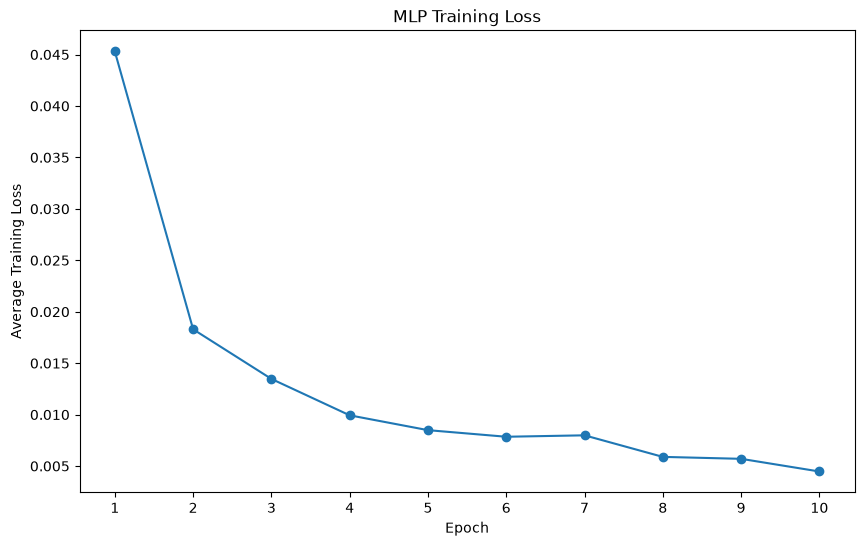

In [65]:
loss_history = []
epochs = 10

def model_training(model, train_loader, epochs):
    for epoch in range(epochs):
        epoch_loss = 0.0
        num_batches = 0

        for X, y in train_loader:
            y_pred = model(X)
            loss = loss_fn(y_pred, y)
            epoch_loss += loss.item()
            num_batches += 1
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        average_loss = epoch_loss / num_batches
        loss_history.append(average_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] - "
            f"Average Loss: {average_loss:.4f}"
        )
    print("Training completed!")

model_training(model, train_loader, epochs)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("MLP Training Loss")
plt.xticks(range(1, len(loss_history) + 1))
plt.show()

## 3. Baseline Testing and Evaluation

### 3.1 Model Performance
After training, we evaluate the MLP on the test dataset to assess its performance on unseen samples. We use several metrics, including accuracy, precision, recall, F1-score, and ROC-AUC, alongside a confusion matrix, to evaluate its malware detection capabilities.

In [101]:
def model_evaluation(model, test_loader):
    model.eval()

    all_predictions = []
    all_probabilities = []
    all_labels = []

    test_loss = 0.0
    num_batches = 0

    with torch.no_grad():
        for X, y in test_loader:
            logits = model(X)

            loss = loss_fn(logits, y.float().view(-1, 1))

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).int()

            test_loss += loss.item()
            num_batches += 1

            all_predictions.extend(predictions.cpu().numpy().flatten())
            all_probabilities.extend(probabilities.cpu().numpy().flatten())
            all_labels.extend(y.cpu().numpy().flatten())

    all_predictions = np.array(all_predictions)
    all_probabilities = np.array(all_probabilities)
    all_labels = np.array(all_labels)

    average_test_loss = test_loss / num_batches

    return average_test_loss, all_labels, all_predictions, all_probabilities

test_loss, y_true, y_pred, y_prob = model_evaluation(model, test_loader)

metrics = {
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        test_loss,
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0),
        roc_auc_score(y_true, y_prob)
    ]
}

metrics_df = pd.DataFrame(metrics)
metrics_df

,Metric,Score
0,Test Loss,0.036800
1,Accuracy,0.994421
2,Precision,0.992081
3,Recall,0.994851
4,F1-Score,0.993464
5,ROC-AUC,0.999176


We have very strong MLP baseline results. The model is learning effectively, and its performance on the test set is excellent:
- **Accuracy (99.44%)**: The model correctly classifies almost all test samples.
- **Precision (99.21%)**: Almost all samples predicted as malicious are actually malicious.
- **Recall (99.49%)**: The model detects almost all actual malicious samples. This is particularly important for malware detection.
- **F1-Score (99.35%)**: Precision and recall are both high.
- **ROC-AUC (99.92%)**: The model has excellent ability to distinguish benign from malicious samples across classification thresholds.

### 3.2 Confusion Matrix

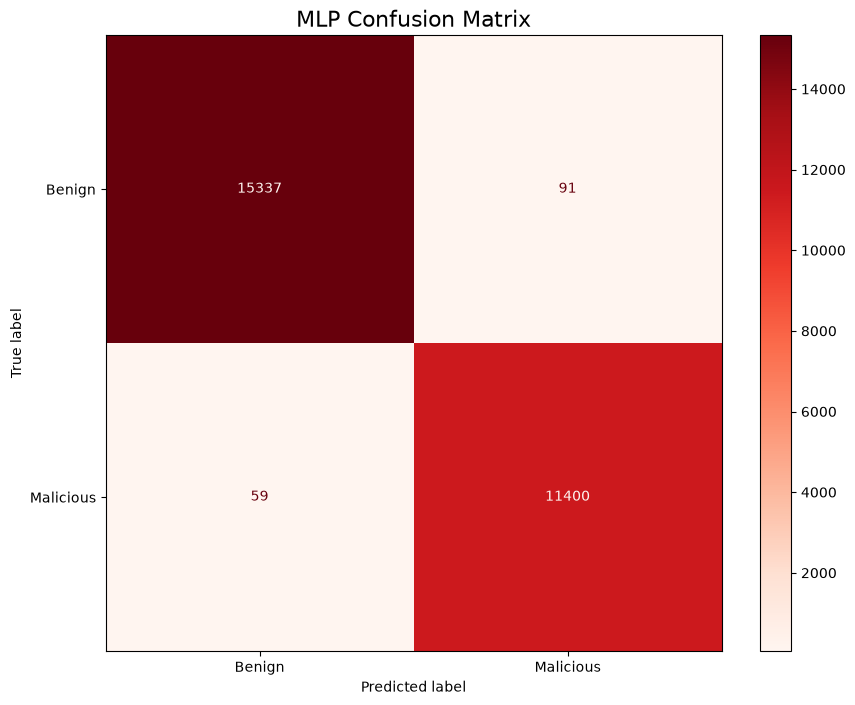

In [78]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malicious"]
)

disp.plot(cmap="Reds", values_format="d", ax=ax)

plt.title("MLP Confusion Matrix", fontsize=16)
plt.show()

The confusion matrix provides a breakdown of the model's classification results:
- **True Negatives (15337)**: Benign samples correctly classified as benign.
- **False Positives (91)**: Benign samples incorrectly classified as malicious.
- **False Negatives (59)**: Malicious samples incorrectly classified as benign.
- **True Positives (11400)**: Malicious samples correctly classified as malicious.

The model correctly classifies the vast majority of both benign and malicious samples, with relatively few false predictions. Notably, only 59 malicious samples are misclassified as benign, indicating strong malware detection performance on the test set.

In [104]:
torch.save(model.state_dict(), MODEL_PATH)

print(f"Model saved successfully to: {MODEL_PATH}")

Model saved successfully to: ../../models/mlp/mlp_baseline.pth


## 3. Conclusion

The MLP baseline achieved strong performance on the test dataset, with an accuracy of 99.44% and an F1-score of 99.35%. The training loss decreased consistently throughout the training process, indicating effective learning. These results establish a strong reference point for the subsequent adversarial experiments.

However, high performance on clean data does not necessarily imply robustness against adversarial manipulation. In the next phase, we will investigate the model's vulnerability to attacks and evaluate whether adversarial training can improve its resilience.